# Automated Irrigation and Crop Health Monitoring System — ML Pipeline
**Dataset:** Crop Recommendation Dataset (Kaggle)
Link: https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset

This notebook covers all three ML tasks for the project:
1. **Classification** — predict the most suitable crop (22 classes)
2. **Prediction** — use the trained model to recommend a crop for new/unseen soil-climate input
3. **Clustering** — group records into agro-climatic zones (unsupervised)



Setup & Upload Dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_style("whitegrid")


In [2]:
# Upload the CSV in Colab. If not running in Colab, edit CSV_PATH below instead.
try:
    from google.colab import files
    uploaded = files.upload()          # pick Crop_recommendation.csv from your computer
    CSV_PATH = list(uploaded.keys())[0]
except ImportError:
    CSV_PATH = "Crop_recommendation.csv"   # local/non-Colab fallback -- edit if needed

df = pd.read_csv(CSV_PATH)
print("Loaded:", CSV_PATH)
df.head()


Saving Crop_recommendation.csv to Crop_recommendation.csv
Loaded: Crop_recommendation.csv


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 1. Exploratory Data Analysis

In [3]:
print("Shape of data:", df.shape)
print("\nNo. of Rows:", df.shape[0])
print("No. of Columns:", df.shape[1])
print("\nColumn data types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Shape of data: (2200, 8)

No. of Rows: 2200
No. of Columns: 8

Column data types:
 N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

Missing values per column:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0


Class distribution (records per crop):
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


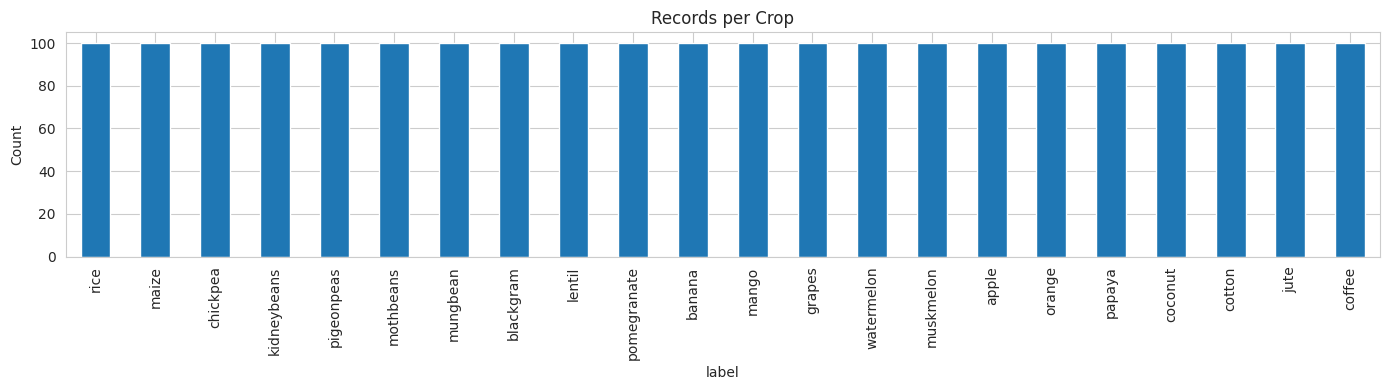

In [4]:
print("Class distribution (records per crop):")
print(df["label"].value_counts())
df["label"].value_counts().plot(kind="bar", figsize=(14,4), title="Records per Crop")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


In [5]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


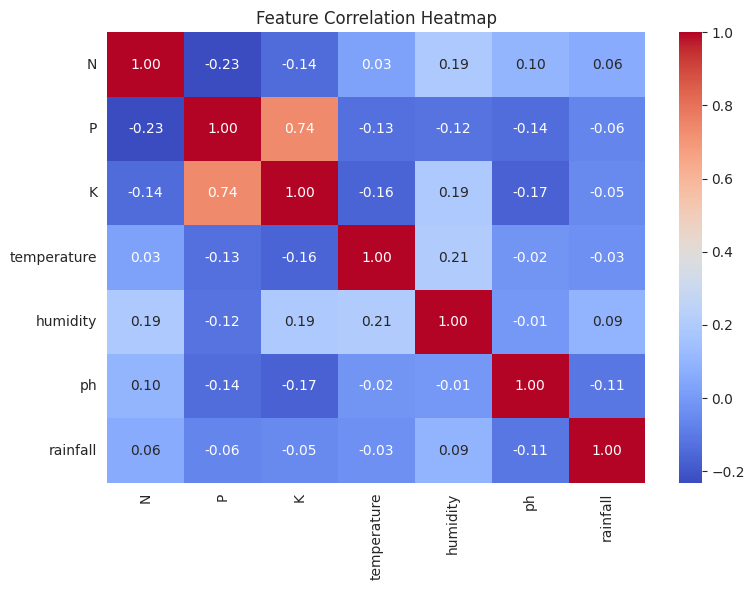

In [6]:
plt.figure(figsize=(8,6))
sns.heatmap(df.drop("label", axis=1).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


## 2. Classification Task
Predict the most suitable crop (target = `label`, 22 classes) from
N, P, K, temperature, humidity, ph, rainfall.

In [7]:
X = df.drop("label", axis=1)
y = df["label"]

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])


Train size: 1760  Test size: 440


In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", random_state=42),
    "Naive Bayes": GaussianNB(),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    results[name] = acc
    print(f"{name:22s} -> Accuracy: {acc*100:.2f}%")

results_df = pd.DataFrame(list(results.items()), columns=["Model", "Accuracy"]).sort_values("Accuracy", ascending=False)
results_df


Logistic Regression    -> Accuracy: 94.77%
Decision Tree          -> Accuracy: 97.95%
Random Forest          -> Accuracy: 99.55%
KNN                    -> Accuracy: 97.73%
SVM                    -> Accuracy: 98.41%
Naive Bayes            -> Accuracy: 99.55%


,Model,Accuracy
5,Naive Bayes,0.995455
2,Random Forest,0.995455
4,SVM,0.984091
1,Decision Tree,0.979545
3,KNN,0.977273
0,Logistic Regression,0.947727


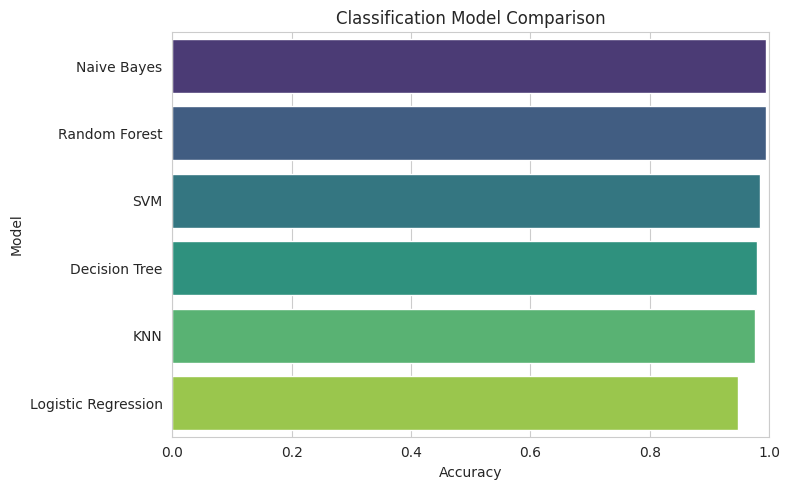

In [9]:
plt.figure(figsize=(8,5))
sns.barplot(data=results_df, x="Accuracy", y="Model", hue="Model", palette="viridis", legend=False)
plt.xlim(0,1)
plt.title("Classification Model Comparison")
plt.tight_layout()
plt.show()


In [10]:
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
print("Best model:", best_name)

y_pred = best_model.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))


Best model: Naive Bayes

Classification Report:

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.91      1.00      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.0

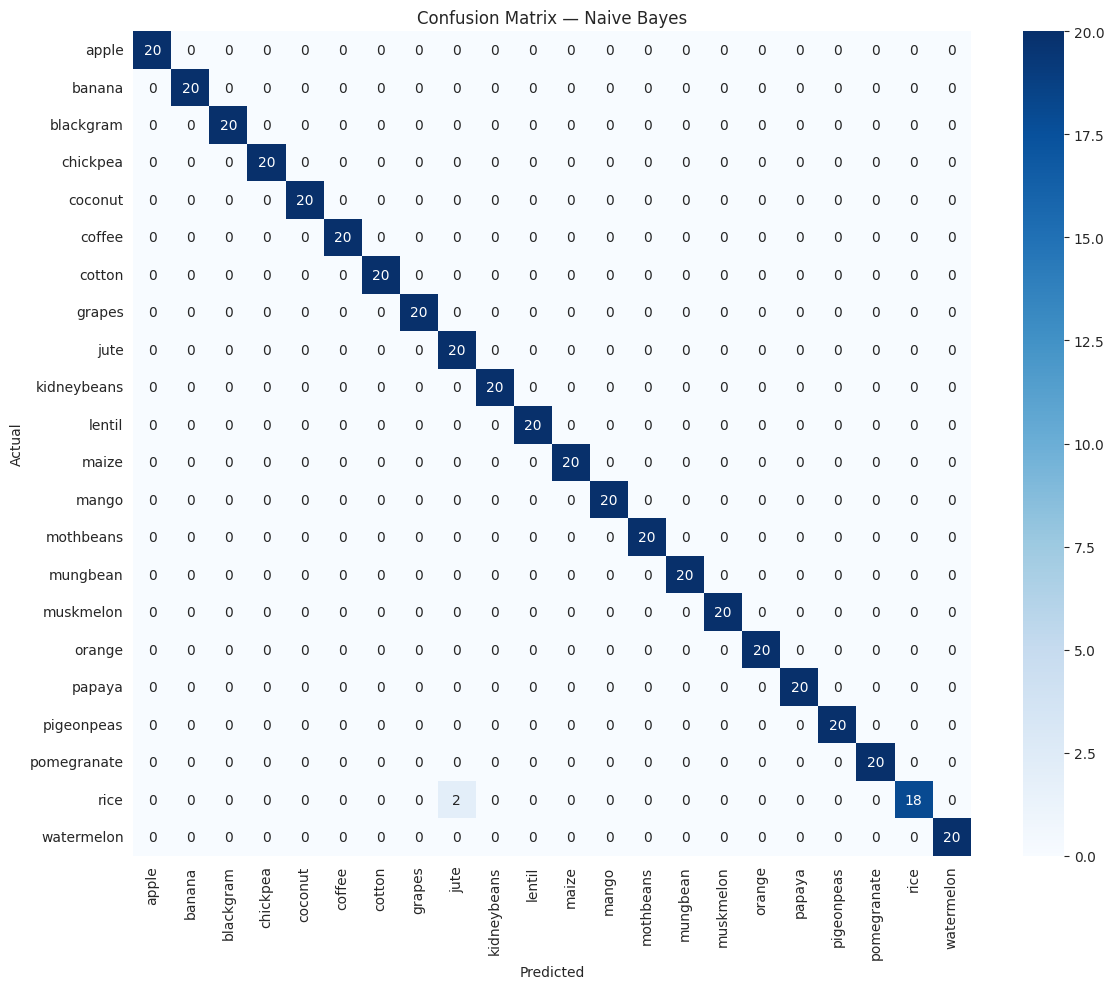

In [11]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_name}")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [12]:
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
    print(importances)
    plt.figure(figsize=(8,5))
    sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="mako", legend=False)
    plt.title(f"Feature Importance — {best_name}")
    plt.tight_layout()
    plt.show()
else:
    print(f"{best_name} does not expose feature_importances_ (not a tree-based model).")


Naive Bayes does not expose feature_importances_ (not a tree-based model).


## 3. Prediction Task
Use the trained classification model to recommend a crop for a brand-new,
unseen soil/climate reading — simulating a live sensor input from the field.

In [13]:
# Replace these values with real sensor readings from your irrigation system
new_samples = pd.DataFrame([
    {"N": 90, "P": 42, "K": 43, "temperature": 20.8, "humidity": 82.0, "ph": 6.5, "rainfall": 202.9},
    {"N": 20, "P": 68, "K": 20, "temperature": 18.5, "humidity": 16.0, "ph": 6.8, "rainfall": 78.0},
])

new_preds = best_model.predict(new_samples)
new_crops = le.inverse_transform(new_preds)

for i, (row, crop) in enumerate(zip(new_samples.to_dict("records"), new_crops), 1):
    print(f"Sample {i}: {row}")
    print(f"  -> Recommended crop: {crop}\n")


Sample 1: {'N': 90, 'P': 42, 'K': 43, 'temperature': 20.8, 'humidity': 82.0, 'ph': 6.5, 'rainfall': 202.9}
  -> Recommended crop: rice

Sample 2: {'N': 20, 'P': 68, 'K': 20, 'temperature': 18.5, 'humidity': 16.0, 'ph': 6.8, 'rainfall': 78.0}
  -> Recommended crop: pigeonpeas



## 4. Clustering Task
Group records into agro-climatic "zones" based on soil/climate similarity —
**without** using the crop label (unsupervised). Useful for identifying broad
zones (e.g., high-fertility/high-rainfall vs. dry/low-nutrient) to support
irrigation planning beyond single-crop recommendation.

In [14]:
X_cluster = df.drop("label", axis=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)


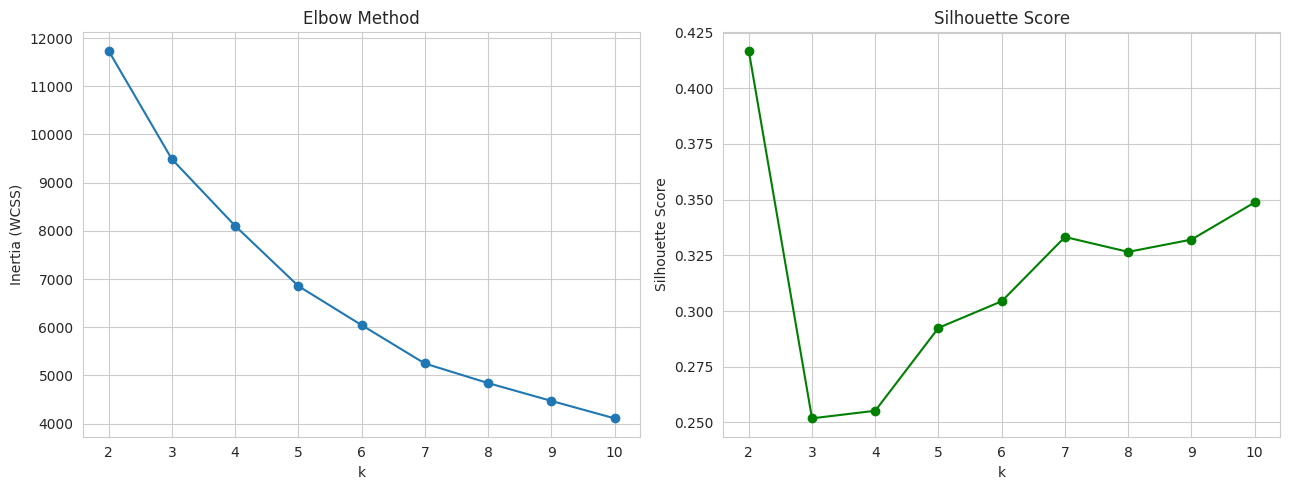

k=2  Inertia=  11738.01  Silhouette=0.4168
k=3  Inertia=   9489.46  Silhouette=0.2519
k=4  Inertia=   8105.86  Silhouette=0.2553
k=5  Inertia=   6856.21  Silhouette=0.2925
k=6  Inertia=   6045.33  Silhouette=0.3044
k=7  Inertia=   5248.63  Silhouette=0.3333
k=8  Inertia=   4842.08  Silhouette=0.3266
k=9  Inertia=   4472.48  Silhouette=0.3321
k=10  Inertia=   4110.15  Silhouette=0.3488


In [15]:
inertia, silhouette = [], []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].plot(list(k_range), inertia, marker="o")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (WCSS)"); axes[0].set_title("Elbow Method")
axes[1].plot(list(k_range), silhouette, marker="o", color="green")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette Score"); axes[1].set_title("Silhouette Score")
plt.tight_layout()
plt.show()

for k, i_, s_ in zip(k_range, inertia, silhouette):
    print(f"k={k}  Inertia={i_:10.2f}  Silhouette={s_:.4f}")


In [16]:
# Choose k: pick the elbow point / highest silhouette that also gives
# interpretable, non-trivial groupings (avoid k that just isolates 1-2 outlier classes)
best_k = 4   # <-- adjust based on YOUR elbow/silhouette plot above
print("Selected k:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)
print("Silhouette score at k =", best_k, ":", silhouette_score(X_scaled, df["cluster"]))
df["cluster"].value_counts().sort_index()


Selected k: 4
Silhouette score at k = 4 : 0.25526916389002857


,count
cluster,
0,797
1,618
2,585
3,200


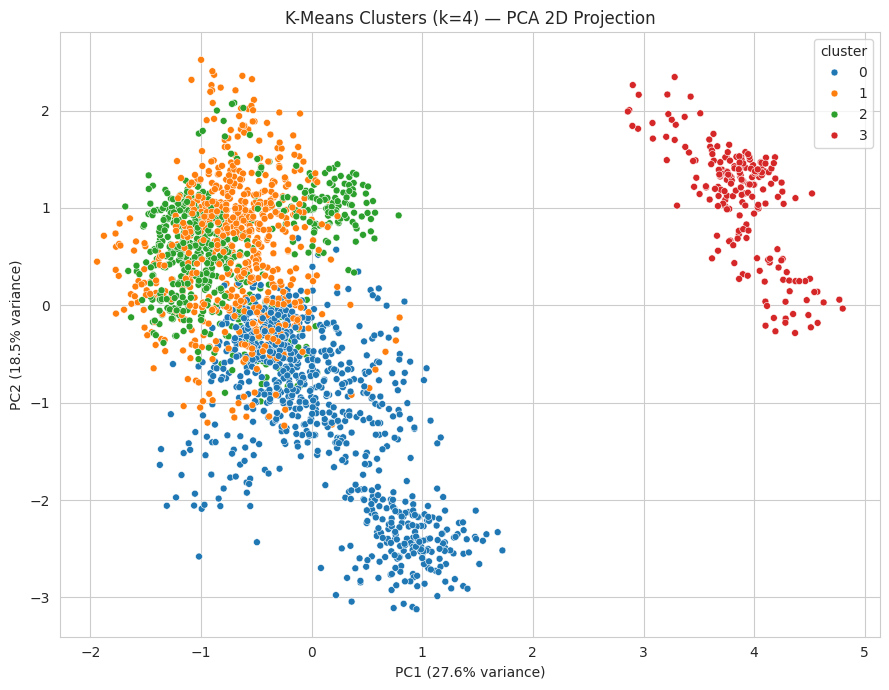

In [17]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df["pca1"], df["pca2"] = X_pca[:,0], X_pca[:,1]

plt.figure(figsize=(9,7))
sns.scatterplot(data=df, x="pca1", y="pca2", hue="cluster", palette="tab10", s=25)
plt.title(f"K-Means Clusters (k={best_k}) — PCA 2D Projection")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout()
plt.show()


In [18]:
profile = df.groupby("cluster")[["N","P","K","temperature","humidity","ph","rainfall"]].mean().round(2)
print("Cluster feature profile (mean values):")
display(profile)

print("\nDominant crops per cluster (top 3, for interpretation only):")
for c in sorted(df["cluster"].unique()):
    top_crops = df[df["cluster"] == c]["label"].value_counts().head(3)
    print(f"  Cluster {c}: {dict(top_crops)}")


Cluster feature profile (mean values):


,N,P,K,temperature,humidity,ph,rainfall
cluster,,,,,,,
0,26.09,57.52,28.64,26.04,50.33,6.54,79.17
1,47.73,32.59,33.37,25.14,85.60,6.55,165.35
2,96.63,42.29,38.42,26.35,80.04,6.46,75.41
3,21.99,133.38,200.00,23.24,87.10,5.98,91.13



Dominant crops per cluster (top 3, for interpretation only):
  Cluster 0: {'chickpea': np.int64(100), 'mango': np.int64(100), 'kidneybeans': np.int64(100)}
  Cluster 1: {'rice': np.int64(100), 'pomegranate': np.int64(100), 'orange': np.int64(100)}
  Cluster 2: {'banana': np.int64(100), 'muskmelon': np.int64(100), 'watermelon': np.int64(100)}
  Cluster 3: {'grapes': np.int64(100), 'apple': np.int64(100)}


## 5. Model Serialisation
Training takes time and needs the dataset. **Serialisation** saves the trained
model into a file so it can be loaded later and used instantly, without retraining.

We save everything needed to reuse the system:
- the best classifier (`.joblib` and `.pkl` formats)
- the `LabelEncoder` (turns predicted numbers back into crop names)
- the feature column order (so inputs are always arranged correctly)
- the `StandardScaler` + `KMeans` model (for the clustering / zone part)

In [19]:
import joblib, pickle, os, sklearn

os.makedirs("saved_models", exist_ok=True)

# --- Classification artefacts ---
joblib.dump(best_model, "saved_models/crop_classifier.joblib")
joblib.dump(le, "saved_models/label_encoder.joblib")
joblib.dump(list(X.columns), "saved_models/feature_columns.joblib")

# --- Clustering artefacts ---
joblib.dump(scaler, "saved_models/scaler.joblib")
joblib.dump(kmeans, "saved_models/kmeans_model.joblib")

# --- Same classifier also saved in .pkl format using pickle ---
with open("saved_models/crop_classifier.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("Model saved:", best_name)
print("scikit-learn version used for training:", sklearn.__version__, "\n")
for fname in sorted(os.listdir("saved_models")):
    size_kb = os.path.getsize(os.path.join("saved_models", fname)) / 1024
    print(f"{fname:28s} {size_kb:9.1f} KB")


Model saved: Naive Bayes
scikit-learn version used for training: 1.6.1 

crop_classifier.joblib             3.9 KB
crop_classifier.pkl                3.6 KB
feature_columns.joblib             0.1 KB
kmeans_model.joblib                9.5 KB
label_encoder.joblib               0.7 KB
scaler.joblib                      1.0 KB


## 6. Reusability of the ML Model
To prove the saved model is reusable, we first **delete the trained model from
memory**, then **load it back from the file** and use it with **no retraining**.

In [20]:
# Keep the original predictions to compare against later
original_pred = best_model.predict(X_test)

# Simulate a brand-new session: remove trained objects from memory
del best_model, le, scaler, kmeans
print("Trained model removed from memory. Loading from disk...\n")

loaded_model  = joblib.load("saved_models/crop_classifier.joblib")
loaded_le     = joblib.load("saved_models/label_encoder.joblib")
feature_cols  = joblib.load("saved_models/feature_columns.joblib")
loaded_scaler = joblib.load("saved_models/scaler.joblib")
loaded_kmeans = joblib.load("saved_models/kmeans_model.joblib")

print("Loaded model type:", type(loaded_model).__name__)
print("Feature order    :", feature_cols)


Trained model removed from memory. Loading from disk...

Loaded model type: GaussianNB
Feature order    : ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']


In [21]:
# Check 1: loaded model must give EXACTLY the same predictions as the original
loaded_pred = loaded_model.predict(X_test)
print("Predictions identical to original model:", np.array_equal(original_pred, loaded_pred))
print(f"Accuracy of loaded model on test set   : {accuracy_score(y_test, loaded_pred)*100:.2f}%")

# Check 2: the .pkl file loads and agrees too
with open("saved_models/crop_classifier.pkl", "rb") as f:
    pkl_model = pickle.load(f)
print("Predictions identical (.pkl version)   :", np.array_equal(original_pred, pkl_model.predict(X_test)))


Predictions identical to original model: True
Accuracy of loaded model on test set   : 99.55%
Predictions identical (.pkl version)   : True


In [22]:
# A reusable function: raw sensor readings in -> full recommendation out
def recommend_crop(N, P, K, temperature, humidity, ph, rainfall, top_n=3):
    sample = pd.DataFrame([[N, P, K, temperature, humidity, ph, rainfall]], columns=feature_cols)

    crop = loaded_le.inverse_transform(loaded_model.predict(sample))[0]
    result = {"recommended_crop": crop}

    if hasattr(loaded_model, "predict_proba"):
        proba = loaded_model.predict_proba(sample)[0]
        top_idx = np.argsort(proba)[::-1][:top_n]
        result["top_choices"] = [(loaded_le.classes_[i], round(float(proba[i]) * 100, 2)) for i in top_idx]

    result["soil_climate_zone"] = int(loaded_kmeans.predict(loaded_scaler.transform(sample))[0])
    return result

# Demo: three different "live sensor" readings
readings = [
    dict(N=90,  P=42, K=43, temperature=20.8, humidity=82.0, ph=6.5, rainfall=202.9),
    dict(N=20,  P=68, K=20, temperature=18.5, humidity=16.0, ph=6.8, rainfall=78.0),
    dict(N=100, P=15, K=50, temperature=27.5, humidity=92.0, ph=6.4, rainfall=25.0),
]
for r in readings:
    print("Input :", r)
    print("Output:", recommend_crop(**r), "\n")


Input : {'N': 90, 'P': 42, 'K': 43, 'temperature': 20.8, 'humidity': 82.0, 'ph': 6.5, 'rainfall': 202.9}
Output: {'recommended_crop': 'rice', 'top_choices': [('rice', 99.57), ('jute', 0.43), ('coffee', 0.0)], 'soil_climate_zone': 1} 

Input : {'N': 20, 'P': 68, 'K': 20, 'temperature': 18.5, 'humidity': 16.0, 'ph': 6.8, 'rainfall': 78.0}
Output: {'recommended_crop': 'pigeonpeas', 'top_choices': [('pigeonpeas', 100.0), ('mothbeans', 0.0), ('kidneybeans', 0.0)], 'soil_climate_zone': 0} 

Input : {'N': 100, 'P': 15, 'K': 50, 'temperature': 27.5, 'humidity': 92.0, 'ph': 6.4, 'rainfall': 25.0}
Output: {'recommended_crop': 'muskmelon', 'top_choices': [('muskmelon', 100.0), ('watermelon', 0.0), ('papaya', 0.0)], 'soil_climate_zone': 2} 



In [23]:
# Batch prediction: many new rows at once using the loaded model
new_batch = pd.DataFrame(readings)
new_batch["predicted_crop"] = loaded_le.inverse_transform(loaded_model.predict(new_batch[feature_cols]))
new_batch


,N,P,K,temperature,humidity,ph,rainfall,predicted_crop
0,90,42,43,20.8,82.0,6.5,202.9,rice
1,20,68,20,18.5,16.0,6.8,78.0,pigeonpeas
2,100,15,50,27.5,92.0,6.4,25.0,muskmelon


## 7. Download the Saved Files


In [24]:
import shutil
shutil.make_archive("saved_models", "zip", "saved_models")

try:
    from google.colab import files
    files.download("saved_models.zip")     # all model files in one zip
except ImportError:
    print("Not running in Colab - the files are in the 'saved_models' folder.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Push to GitHub** (run in your computer's terminal, inside the project folder):

```bash
git init
git add Crop_ML_Project.ipynb saved_models/ predict.py requirements.txt README.md
git commit -m "Crop recommendation ML project with serialised models"
git branch -M main
git remote add origin https://github.com/<your-username>/<your-repo>.git
git push -u origin main
```
*(Or without commands: GitHub repo → Add file → Upload files → drag the files in → Commit.)*

**Reusing the model from the GitHub repo in any new notebook / script:**

```python
import joblib, pandas as pd
model = joblib.load("saved_models/crop_classifier.joblib")
le    = joblib.load("saved_models/label_encoder.joblib")
cols  = joblib.load("saved_models/feature_columns.joblib")

sample = pd.DataFrame([[90, 42, 43, 20.8, 82.0, 6.5, 202.9]], columns=cols)
print(le.inverse_transform(model.predict(sample))[0])
```

## 8. Summary

| Task | Method | Result |
|---|---|---|
| Classification | Best of 6 models compared | See accuracy table in Section 2 |
| Prediction | Trained model on new input | See Section 3 output |
| Clustering | K-Means (k chosen from elbow/silhouette) | See Section 4 cluster profile |
| Serialisation | joblib + pickle | Model, encoder, scaler, K-Means saved in `saved_models/` |
| Reusability | Loaded from file, no retraining | Identical predictions confirmed (Section 6) |

This notebook covers the full ML workflow for the *Automated Irrigation and Crop
Health Monitoring System Using Machine Learning* project: EDA, classification,
prediction, clustering, model serialisation and reuse.